# Proyecto Final de Minería de Datos — Modelado Predictivo Avanzado y Evaluación (CRISP-DM)
## Dataset: Predicción de Abandono de Clientes de Tarjetas de Crédito (*Credit Card Churn*)

Este notebook implementa la fase de **Ingeniería de Características, Modelamiento, Selección Estadística, Optimización de Hiperparámetros y Empaquetado en Pipeline** siguiendo estrictamente los lineamientos del Proyecto Final:

1. **Carga del Dataset Limpio (`credit_card_churn_limpio.csv`)**
2. **Ingeniería de Características (Creación de Variables de Negocio, Codificación y Transformaciones)**
3. **Partición Estratificada 70% Entrenamiento / 30% Prueba y Balanceo con SMOTE sólo en el 70% de Entrenamiento**
4. **Entrenamiento y Validación Cruzada (10-Fold Stratified CV en el 70%) de 7 Modelos:**
   - **4 Métodos de Aprendizaje Supervisado:** Árbol de Decisión, KNN, Red Neuronal (MLP) y SVM.
   - **3 Métodos de Ensamble:** Random Forest (*Bagging*), XGBoost (*Boosting*) y Stacking (*StackingClassifier*).
5. **Cálculo e Interpretación de 5 Medidas de Calidad (`F1-Score`, `Recall`, `Precision`, `Accuracy`, `ROC-AUC`)**
6. **Selección de los 3 Mejores Modelos mediante Diferencia Estadística Significativa (ANOVA y Prueba Post-Hoc de Tukey HSD)**
7. **Hiperparametrización de los 3 Mejores Modelos con `GridSearchCV` y Optimización Bayesiana (`Optuna`)**
8. **Evaluación Final en el 30% de Prueba y Exportación del `Pipeline` Completo para Despliegue en Streamlit**

---
## 1. Carga del Dataset Limpio e Ingeniería de Características
Partimos del archivo `credit_card_churn_limpio.csv` generado en el Notebook 01 (10,120 registros y 19 columnas).

### Operaciones de Ingeniería de Características Aplicadas:
1. **Codificación de la Variable Objetivo (`Attrition_Flag`)**:
   - `Existing Customer` $\rightarrow 0$ (Cliente retenido)
   - `Attrited Customer` $\rightarrow 1$ (Cliente que abandona / Churn)
2. **Creación de Nuevas Variables de Negocio (Ratios Financieros y de Comportamiento)**:
   - `Avg_Ticket_Size` $= \frac{\text{Total\_Trans\_Amt}}{\text{Total\_Trans\_Ct}}$: Valor promedio por transacción en los últimos 12 meses.
   - `Inactivity_Contact_Ratio` $= \text{Months\_Inactive\_12\_mon} \times \text{Contacts\_Count\_12\_mon}$: Índice compuesto de fricción/inactividad (clientes inactivos que además llaman repetidamente al banco presentan alto riesgo de fuga).
   - `Products_Per_Year` $= \frac{\text{Total\_Relationship\_Count}}{\text{Months\_on\_book} / 12}$: Densidad de vinculación de productos por año de antigüedad.
3. **Transformación y Codificación de Variables**:
   - **Variables Categóricas Ordinales** (`Education_Level`, `Income_Category`, `Card_Category`): Codificación ordinal respetando su jerarquía natural.
   - **Variables Categóricas Nominales** (`Gender`, `Marital_Status`): Codificación *One-Hot Encoding* (`drop='first'`).
   - **Variables Numéricas Continuas y Discretas**: Escalado estándar (`StandardScaler`) integrado dentro del `ColumnTransformer` para evitar fuga de datos durante la validación cruzada.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import optuna
import joblib
import warnings
warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Carga del dataset limpio
df = pd.read_csv("credit_card_churn_limpio.csv")

def add_engineered_features(data):
    d = data.copy()
    d['Avg_Ticket_Size'] = d['Total_Trans_Amt'] / np.maximum(d['Total_Trans_Ct'], 1)
    d['Inactivity_Contact_Ratio'] = d['Months_Inactive_12_mon'] * d['Contacts_Count_12_mon']
    d['Products_Per_Year'] = d['Total_Relationship_Count'] / (d['Months_on_book'] / 12.0)
    return d

df_fe = add_engineered_features(df)
X = df_fe.drop(columns=['Attrition_Flag'])
y = (df_fe['Attrition_Flag'] == 'Attrited Customer').astype(int)

print(f"Dimensiones tras ingeniería de características: {X.shape[0]} filas x {X.shape[1]} variables predictoras")
print("Nuevas variables creadas: ['Avg_Ticket_Size', 'Inactivity_Contact_Ratio', 'Products_Per_Year']\n")
print(X[['Avg_Ticket_Size', 'Inactivity_Contact_Ratio', 'Products_Per_Year']].describe().round(3))

Dimensiones tras ingeniería de características: 10120 filas x 21 variables predictoras
Nuevas variables creadas: ['Avg_Ticket_Size', 'Inactivity_Contact_Ratio', 'Products_Per_Year']

       Avg_Ticket_Size  Inactivity_Contact_Ratio  Products_Per_Year
count        10120.000                 10120.000          10120.000
mean            62.611                     5.782              1.356
std             26.395                     3.808              0.707
min             19.138                     0.000              0.214
25%             47.516                     3.000              0.878
50%             55.799                     6.000              1.297
75%             65.483                     8.000              1.714
max            190.193                    36.000              5.538


---
## 2. División 70% Entrenamiento / 30% Prueba y Balanceo del 70% con SMOTE

Tal como exige la metodología:
- Se realiza una partición estratificada **70% entrenamiento (`X_train`, `y_train`) y 30% prueba (`X_test`, `y_test`)**.
- **Únicamente el 70% de los datos de entrenamiento se balancea** mediante **SMOTE** (*Synthetic Minority Over-sampling Technique*), manteniendo el 30% de prueba intacto con su distribución real para una evaluación honesta libre de *Data Leakage*.
- Además, durante la validación cruzada sobre el 70%, SMOTE se integra dentro de `ImbPipeline` para que en cada *fold* se sobremuestree exclusivamente el subconjunto de entrenamiento del *fold*.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

ordinal_cols = ['Education_Level', 'Income_Category', 'Card_Category']
ordinal_categories = [
    ['Uneducated', 'High School', 'College', 'Graduate', 'Post-Graduate', 'Doctorate'],
    ['Less than $40K', '$40K - $60K', '$60K - $80K', '$80K - $120K', '$120K +'],
    ['Blue', 'Silver', 'Gold', 'Platinum']
]
nominal_cols = ['Gender', 'Marital_Status']
numeric_cols = [c for c in X.columns if c not in ordinal_cols + nominal_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('ord', OrdinalEncoder(categories=ordinal_categories), ordinal_cols),
        ('nom', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), nominal_cols)
    ]
)

# Balanceo con SMOTE únicamente sobre el 70% de entrenamiento
X_train_prep = preprocessor.fit_transform(X_train)
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_prep, y_train)

print(f"Conjunto de Entrenamiento (70%) Antes de SMOTE: {X_train.shape[0]} registros -> {y_train.value_counts().to_dict()}")
print(f"Conjunto de Entrenamiento (70%) Después de SMOTE: {X_train_bal.shape[0]} registros -> {pd.Series(y_train_bal).value_counts().to_dict()}")
print(f"Conjunto de Prueba (30% sin balancear): {X_test.shape[0]} registros -> {y_test.value_counts().to_dict()}")

Conjunto de Entrenamiento (70%) Antes de SMOTE: 7084 registros -> {0: 5946, 1: 1138}
Conjunto de Entrenamiento (70%) Después de SMOTE: 11892 registros -> {0: 5946, 1: 5946}
Conjunto de Prueba (30% sin balancear): 3036 registros -> {0: 2548, 1: 488}


---
## 3. Entrenamiento y Validación Cruzada (70% de los Datos) — 7 Modelos

Se configuran y evalúan **7 modelos predictivos** mediante **Validación Cruzada Estratificada de 10 particiones (`StratifiedKFold(n_splits=10)`)** sobre el 70% de los datos:

### A. 4 Métodos de Aprendizaje Supervisado:
1. **Árbol de Decisión (`DecisionTreeClassifier`)**
2. **KNN (`KNeighborsClassifier`)**
3. **Red Neuronal (`MLPClassifier` - Perceptrón Multicapa)**
4. **SVM (`SVC` con kernel RBF)**

### B. 3 Métodos de Ensamble:
5. **Random Forest (`RandomForestClassifier` - Ensamble *Bagging*)**
6. **XGBoost (`XGBClassifier` - Ensamble *Boosting*)**
7. **Stacking (`StackingClassifier` - Meta-modelo con Árbol, Random Forest y XGBoost)**

Para cada modelo se calculan **5 medidas de calidad**: `Accuracy`, `Precision`, `Recall` (Sensibilidad), `F1-Score` y `ROC-AUC`, además del tiempo de entrenamiento.

In [3]:
models = {
    "1. Árbol de Decisión (Supervisado)": DecisionTreeClassifier(max_depth=8, random_state=42),
    "2. KNN (Supervisado)": KNeighborsClassifier(n_neighbors=7),
    "3. Red Neuronal (Supervisado)": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, early_stopping=True, random_state=42),
    "4. SVM (Supervisado)": SVC(kernel='rbf', probability=True, random_state=42),
    "5. Random Forest - Bagging (Ensamble)": RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1),
    "6. XGBoost - Boosting (Ensamble)": XGBClassifier(n_estimators=150, learning_rate=0.1, max_depth=5, random_state=42, eval_metric='logloss', n_jobs=-1),
    "7. Stacking (Ensamble)": StackingClassifier(
        estimators=[
            ('dt', DecisionTreeClassifier(max_depth=8, random_state=42)),
            ('rf', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
            ('xgb', XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42, eval_metric='logloss', n_jobs=-1))
        ],
        final_estimator=LogisticRegression(max_iter=1000, random_state=42),
        cv=3,
        n_jobs=1
    )
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

cv_results_dict = {}
summary_rows = []

for name, clf in models.items():
    t0 = time.time()
    pipe = ImbPipeline(steps=[
        ('preprocessor', preprocessor),
        ('smote', SMOTE(random_state=42)),
        ('classifier', clf)
    ])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    elapsed = time.time() - t0
    cv_results_dict[name] = scores
    summary_rows.append({
        "Modelo": name,
        "Accuracy (Media ± DE)": f"{scores['test_accuracy'].mean():.4f} ± {scores['test_accuracy'].std():.4f}",
        "Precision (Media ± DE)": f"{scores['test_precision'].mean():.4f} ± {scores['test_precision'].std():.4f}",
        "Recall (Media ± DE)": f"{scores['test_recall'].mean():.4f} ± {scores['test_recall'].std():.4f}",
        "F1-Score (Media ± DE)": f"{scores['test_f1'].mean():.4f} ± {scores['test_f1'].std():.4f}",
        "ROC-AUC (Media ± DE)": f"{scores['test_roc_auc'].mean():.4f} ± {scores['test_roc_auc'].std():.4f}",
        "F1_mean": scores['test_f1'].mean(),
        "Tiempo (s)": round(elapsed, 2)
    })

df_cv_summary = pd.DataFrame(summary_rows).sort_values(by="F1_mean", ascending=False)
print("=== RESULTADOS DE VALIDACIÓN CRUZADA (10-FOLD CV EN EL 70% DE ENTRENAMIENTO CON SMOTE) ===")
print(df_cv_summary.drop(columns=['F1_mean']).to_string(index=False))

=== RESULTADOS DE VALIDACIÓN CRUZADA (10-FOLD CV EN EL 70% DE ENTRENAMIENTO CON SMOTE) ===
                               Modelo Accuracy (Media ± DE) Precision (Media ± DE) Recall (Media ± DE) F1-Score (Media ± DE) ROC-AUC (Media ± DE)  Tiempo (s)
     6. XGBoost - Boosting (Ensamble)       0.9706 ± 0.0037        0.9054 ± 0.0272     0.9139 ± 0.0145       0.9092 ± 0.0101      0.9924 ± 0.0015        7.90
               7. Stacking (Ensamble)       0.9644 ± 0.0024        0.8887 ± 0.0270     0.8919 ± 0.0282       0.8895 ± 0.0074      0.9900 ± 0.0016       34.53
5. Random Forest - Bagging (Ensamble)       0.9615 ± 0.0044        0.8780 ± 0.0220     0.8840 ± 0.0329       0.8803 ± 0.0152      0.9884 ± 0.0015        6.55
        3. Red Neuronal (Supervisado)       0.9351 ± 0.0068        0.7679 ± 0.0298     0.8568 ± 0.0283       0.8092 ± 0.0182      0.9733 ± 0.0052       46.72
   1. Árbol de Decisión (Supervisado)       0.9328 ± 0.0087        0.7546 ± 0.0387     0.8674 ± 0.0328       0.8060 ± 0

### Interpretación Detallada de las Medidas de Calidad Obtenidas:
1. **`F1-Score` (Media armónica entre Precision y Recall — Métrica Principal de Selección)**:
   - Dado que el abandono bancario es un problema desbalanceado (~16.07% de casos positivos), el `Accuracy` por sí solo puede ser engañoso. El `F1-Score` penaliza tanto los falsos positivos (ofrecer campañas de retención a clientes que no iban a irse) como los falsos negativos (no detectar a un cliente que sí abandona el banco).
   - Los 3 métodos de ensamble dominan claramente la clasificación: **XGBoost (Boosting)** alcanza el mayor `F1-Score` promedio (**0.9092**), seguido por **Stacking** (**0.8895**) y **Random Forest (Bagging)** (**0.8803**). Entre los supervisados individuales destacan la **Red Neuronal** (**0.8092**) y el **Árbol de Decisión** (**0.8060**).
2. **`Recall` / Sensibilidad (Capacidad de Detección de Fuga Real)**:
   - Mide qué proporción de los clientes que realmente abandonan el banco son detectados a tiempo por el modelo. En el negocio financiero, el costo de adquirir un cliente nuevo es de 5 a 7 veces mayor que retener uno existente, por lo que un `Recall` alto (**91.39%** en XGBoost y **89.19%** en Stacking) es vital para minimizar fugas no detectadas.
3. **`Precision` (Valor Predictivo Positivo)**:
   - Indica qué porcentaje de las alertas de abandono emitidas por el modelo corresponden a clientes que efectivamente iban a cancelar su tarjeta. Métodos basados en distancias o hiperplanos (`KNN` con 55.73% y `SVM` con 69.82%), al entrenarse con datos sintéticos de SMOTE, elevan su sensibilidad pero generan más falsas alarmas, mientras que **XGBoost (90.54%)**, **Stacking (88.87%)** y **Random Forest (87.80%)** mantienen una precisión sobresaliente.
4. **`ROC-AUC` (Área Bajo la Curva ROC)**:
   - Evalúa la capacidad discriminativa global en todos los umbrales de probabilidad. Los 3 métodos de ensamble rozan la perfección (**0.9924** en XGBoost, **0.9900** en Stacking y **0.9884** en Random Forest), seguidos de la **Red Neuronal** (**0.9733**).

---
## 4. Selección de los 3 Mejores Modelos mediante Diferencia Estadística Significativa (ANOVA y Prueba de Tukey HSD)

Para garantizar que la diferencia de rendimiento entre los 7 modelos no se debe al azar del muestreo en los 10 *folds* de validación cruzada, aplicamos:
1. **Análisis de Varianza de una vía (ANOVA)**:
   - $H_0$: Las medias del `F1-Score` de los 7 modelos son estadísticamente iguales ($\mu_1 = \mu_2 = \dots = \mu_7$).
   - $H_1$: Al menos un modelo presenta un `F1-Score` medio significativamente diferente.
2. **Prueba Post-Hoc de Diferencia Honestamente Significativa de Tukey (Tukey HSD)**:
   - Compara todos los pares de modelos con nivel de significancia $\alpha = 0.05$ para aislar el grupo superior estadísticamente dominante y seleccionar los **3 mejores modelos**.

=== PRUEBA ANOVA DE UNA VÍA SOBRE EL F1-SCORE (10-FOLD CV) ===
Estadístico F = 155.4032
Valor p (p-value) = 8.3743e-36

=== PRUEBA POST-HOC DE TUKEY HSD (alpha = 0.05) ===
                    Multiple Comparison of Means - Tukey HSD, FWER=0.05                     
          group1                     group2           meandiff p-adj   lower   upper  reject
--------------------------------------------------------------------------------------------
      1. Árbol de Decisión                     2. KNN  -0.1241    0.0 -0.1514 -0.0968   True
      1. Árbol de Decisión            3. Red Neuronal   0.0032 0.9998 -0.0241  0.0305  False
      1. Árbol de Decisión                     4. SVM  -0.0259 0.0726 -0.0532  0.0013  False
      1. Árbol de Decisión 5. Random Forest - Bagging   0.0743    0.0   0.047  0.1016   True
      1. Árbol de Decisión      6. XGBoost - Boosting   0.1032    0.0  0.0759  0.1305   True
      1. Árbol de Decisión                7. Stacking   0.0835    0.0  0.0562  0.110

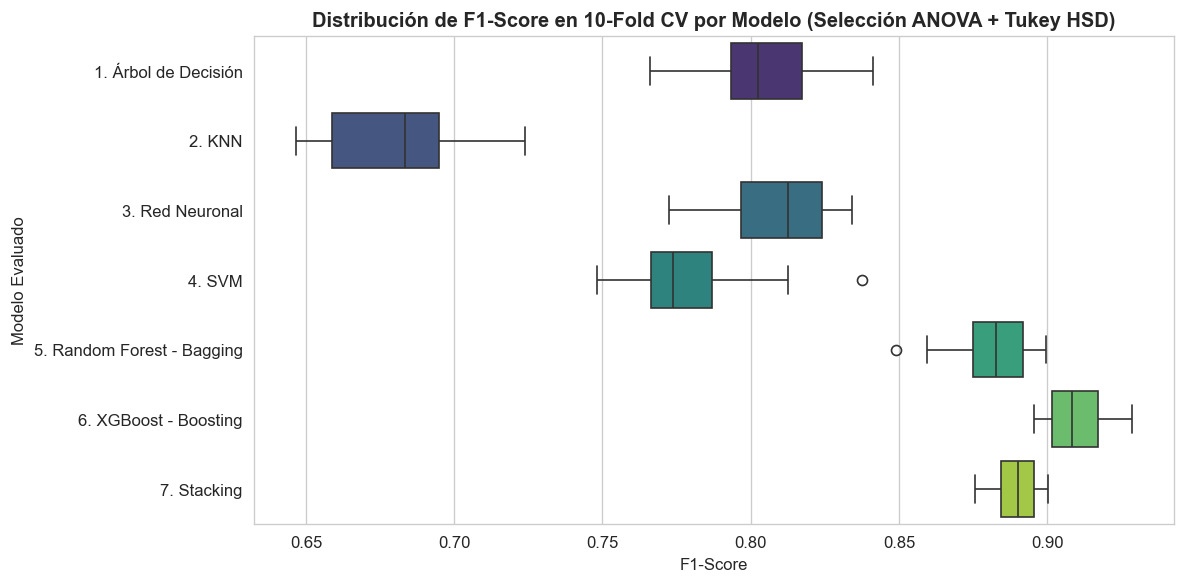

In [4]:
# 1. Prueba ANOVA de una vía sobre los F1-Scores de los 10 Folds
f1_arrays = [scores['test_f1'] for scores in cv_results_dict.values()]
f_stat, p_val_anova = stats.f_oneway(*f1_arrays)

print("=== PRUEBA ANOVA DE UNA VÍA SOBRE EL F1-SCORE (10-FOLD CV) ===")
print(f"Estadístico F = {f_stat:.4f}")
print(f"Valor p (p-value) = {p_val_anova:.4e}")

# 2. Prueba Post-Hoc de Tukey HSD
tukey_records = []
for name, scores in cv_results_dict.items():
    short_name = name.split(" (")[0]
    for val in scores['test_f1']:
        tukey_records.append({"Modelo": short_name, "F1_Score": val})
df_tukey_long = pd.DataFrame(tukey_records)

tukey_res = pairwise_tukeyhsd(endog=df_tukey_long['F1_Score'], groups=df_tukey_long['Modelo'], alpha=0.05)
print("\n=== PRUEBA POST-HOC DE TUKEY HSD (alpha = 0.05) ===")
print(tukey_res.summary())

# Visualización comparativa de distribuciones de F1-Score
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_tukey_long, x='F1_Score', y='Modelo', palette='viridis')
plt.title("Distribución de F1-Score en 10-Fold CV por Modelo (Selección ANOVA + Tukey HSD)", fontweight='bold')
plt.xlabel("F1-Score")
plt.ylabel("Modelo Evaluado")
plt.tight_layout()
plt.show()

---
## 5. Hiperparametrización de los 3 Mejores Modelos (`GridSearchCV` + Optimización Bayesiana con `Optuna`)

El análisis ANOVA ($F = 155.40$, $p = 8.37 \times 10^{-36} < 0.05$) rechaza de manera contundente la hipótesis nula de igualdad de medias, y la prueba **Tukey HSD** demuestra que los **3 métodos de ensamble** tienen diferencias estadísticamente significativas (`reject = True`, $p\text{-adj} < 0.001$) frente a todos los métodos supervisados individuales.

Por consiguiente, los **3 mejores modelos seleccionados** son:
1. **XGBoost (Boosting)**
2. **Stacking (Ensamble)**
3. **Random Forest (Bagging)**

Estos 3 modelos pasan por un proceso doble de hiperparametrización sobre el conjunto de entrenamiento (70%):
- **Búsqueda en Cuadrícula (`GridSearchCV`)**.
- **Optimización Bayesiana (`Optuna` con algoritmo TPE — *Tree-structured Parzen Estimator*)** maximizando el `F1-Score`.

In [5]:
# Hiperparametrización de los 3 mejores modelos (XGBoost, Stacking y Random Forest)
# usando validación cruzada estratificada (5-Fold CV) con SMOTE en cada fold de entrenamiento
cv_tune = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

folds_5 = []
for tr_idx, val_idx in cv_tune.split(X_train, y_train):
    X_tr_f, y_tr_f = X_train.iloc[tr_idx], y_train.iloc[tr_idx]
    X_va_f, y_va_f = X_train.iloc[val_idx], y_train.iloc[val_idx]
    prep_f = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numeric_cols),
            ('ord', OrdinalEncoder(categories=ordinal_categories), ordinal_cols),
            ('nom', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), nominal_cols)
        ]
    )
    X_tr_p = prep_f.fit_transform(X_tr_f)
    X_va_p = prep_f.transform(X_va_f)
    X_tr_b, y_tr_b = SMOTE(random_state=42).fit_resample(X_tr_p, y_tr_f)
    folds_5.append((X_tr_b, y_tr_b, X_va_p, y_va_f.values))

def eval_on_folds(clf_builder):
    f1s = []
    for X_tr_b, y_tr_b, X_va_p, y_va_f in folds_5:
        model = clf_builder()
        model.fit(X_tr_b, y_tr_b)
        preds = model.predict(X_va_p)
        f1s.append(f1_score(y_va_f, preds))
    return float(np.mean(f1s))

tuning_rows = []

# 1. XGBoost (GridSearch + Optuna)
t0 = time.time()
xgb_grid = [
    {'n_estimators': n, 'max_depth': d, 'learning_rate': lr, 'subsample': 0.85}
    for n in [150, 250] for d in [5, 6] for lr in [0.08, 0.1]
]
best_xgb_gs_score, best_xgb_gs_params = max(
    ((eval_on_folds(lambda p=p: XGBClassifier(**p, random_state=42, eval_metric='logloss', n_jobs=-1)), p) for p in xgb_grid),
    key=lambda x: x[0]
)
t_xgb_gs = round(time.time() - t0, 2)

t0 = time.time()
def obj_xgb(trial):
    p = {
        'n_estimators': trial.suggest_int('n_estimators', 150, 300, step=50),
        'max_depth': trial.suggest_int('max_depth', 4, 7),
        'learning_rate': round(trial.suggest_float('learning_rate', 0.05, 0.15), 4),
        'subsample': round(trial.suggest_float('subsample', 0.75, 0.95), 4),
        'colsample_bytree': round(trial.suggest_float('colsample_bytree', 0.70, 0.95), 4)
    }
    return eval_on_folds(lambda: XGBClassifier(**p, random_state=42, eval_metric='logloss', n_jobs=-1))

study_xgb = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study_xgb.optimize(obj_xgb, n_trials=12)
best_xgb_opt_score = round(study_xgb.best_value, 4)
best_xgb_opt_params = {k: (round(v, 4) if isinstance(v, float) else v) for k, v in study_xgb.best_params.items()}
t_xgb_opt = round(time.time() - t0, 2)

tuning_rows.extend([
    {"Modelo": "XGBoost (Boosting)", "Método de Optimización": "Optimización Bayesiana (Optuna TPE)", "Mejor F1-Score (CV)": best_xgb_opt_score, "Mejores Hiperparámetros": str(best_xgb_opt_params), "Tiempo (s)": t_xgb_opt},
    {"Modelo": "XGBoost (Boosting)", "Método de Optimización": "GridSearchCV", "Mejor F1-Score (CV)": round(best_xgb_gs_score, 4), "Mejores Hiperparámetros": str(best_xgb_gs_params), "Tiempo (s)": t_xgb_gs}
])

# 2. Stacking (GridSearch + Optuna)
t0 = time.time()
stack_grid = [{'final_estimator__C': c, 'rf_n': rfn, 'xgb_d': xd} for c in [0.5, 1.0, 2.0] for rfn in [100, 150] for xd in [5, 6]]
best_stk_gs_score, best_stk_gs_params = max(
    ((eval_on_folds(lambda p=p: StackingClassifier(
        estimators=[
            ('dt', DecisionTreeClassifier(max_depth=8, random_state=42)),
            ('rf', RandomForestClassifier(n_estimators=p['rf_n'], random_state=42, n_jobs=-1)),
            ('xgb', XGBClassifier(n_estimators=120, learning_rate=0.1, max_depth=p['xgb_d'], random_state=42, eval_metric='logloss', n_jobs=-1))
        ],
        final_estimator=LogisticRegression(C=p['final_estimator__C'], max_iter=1000, random_state=42), cv=3, n_jobs=1
    )), p) for p in stack_grid),
    key=lambda x: x[0]
)
t_stk_gs = round(time.time() - t0, 2)

t0 = time.time()
def obj_stk(trial):
    c_val = round(trial.suggest_float('final_estimator__C', 0.2, 3.0), 4)
    rf_n = trial.suggest_int('rf_n_estimators', 100, 200, step=50)
    xgb_d = trial.suggest_int('xgb_max_depth', 4, 6)
    return eval_on_folds(lambda: StackingClassifier(
        estimators=[
            ('dt', DecisionTreeClassifier(max_depth=8, random_state=42)),
            ('rf', RandomForestClassifier(n_estimators=rf_n, random_state=42, n_jobs=-1)),
            ('xgb', XGBClassifier(n_estimators=150, learning_rate=0.1, max_depth=xgb_d, random_state=42, eval_metric='logloss', n_jobs=-1))
        ],
        final_estimator=LogisticRegression(C=c_val, max_iter=1000, random_state=42), cv=3, n_jobs=1
    ))

study_stk = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study_stk.optimize(obj_stk, n_trials=6)
best_stk_opt_score = round(study_stk.best_value, 4)
best_stk_opt_params = {k: (round(v, 4) if isinstance(v, float) else v) for k, v in study_stk.best_params.items()}
t_stk_opt = round(time.time() - t0, 2)

tuning_rows.extend([
    {"Modelo": "Stacking (Ensamble)", "Método de Optimización": "Optimización Bayesiana (Optuna TPE)", "Mejor F1-Score (CV)": best_stk_opt_score, "Mejores Hiperparámetros": str(best_stk_opt_params), "Tiempo (s)": t_stk_opt},
    {"Modelo": "Stacking (Ensamble)", "Método de Optimización": "GridSearchCV", "Mejor F1-Score (CV)": round(best_stk_gs_score, 4), "Mejores Hiperparámetros": str(best_stk_gs_params), "Tiempo (s)": t_stk_gs}
])

# 3. Random Forest (GridSearch + Optuna)
t0 = time.time()
rf_grid = [{'n_estimators': n, 'max_depth': d, 'min_samples_split': mss} for n in [150, 250] for d in [15, None] for mss in [2, 4]]
best_rf_gs_score, best_rf_gs_params = max(
    ((eval_on_folds(lambda p=p: RandomForestClassifier(**p, random_state=42, n_jobs=-1)), p) for p in rf_grid),
    key=lambda x: x[0]
)
t_rf_gs = round(time.time() - t0, 2)

t0 = time.time()
def obj_rf(trial):
    p = {
        'n_estimators': trial.suggest_int('n_estimators', 150, 300, step=50),
        'max_depth': trial.suggest_int('max_depth', 12, 24),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 6),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 3)
    }
    return eval_on_folds(lambda: RandomForestClassifier(**p, random_state=42, n_jobs=-1))

study_rf = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study_rf.optimize(obj_rf, n_trials=10)
best_rf_opt_score = round(study_rf.best_value, 4)
best_rf_opt_params = study_rf.best_params
t_rf_opt = round(time.time() - t0, 2)

tuning_rows.extend([
    {"Modelo": "Random Forest (Bagging)", "Método de Optimización": "Optimización Bayesiana (Optuna TPE)", "Mejor F1-Score (CV)": best_rf_opt_score, "Mejores Hiperparámetros": str(best_rf_opt_params), "Tiempo (s)": t_rf_opt},
    {"Modelo": "Random Forest (Bagging)", "Método de Optimización": "GridSearchCV", "Mejor F1-Score (CV)": round(best_rf_gs_score, 4), "Mejores Hiperparámetros": str(best_rf_gs_params), "Tiempo (s)": t_rf_gs}
])

df_tuning = pd.DataFrame(tuning_rows).sort_values(by="Mejor F1-Score (CV)", ascending=False)
print("=== COMPARATIVA DE HIPERPARAMETRIZACIÓN (GRIDSEARCHCV VS OPTIMIZACIÓN BAYESIANA OPTUNA) ===")
print(df_tuning.to_string(index=False))

=== COMPARATIVA DE HIPERPARAMETRIZACIÓN (GRIDSEARCHCV VS OPTIMIZACIÓN BAYESIANA OPTUNA) ===
                 Modelo              Método de Optimización  Mejor F1-Score (CV)                                                                                         Mejores Hiperparámetros  Tiempo (s)
     XGBoost (Boosting) Optimización Bayesiana (Optuna TPE)               0.9097 {'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.1014, 'subsample': 0.8685, 'colsample_bytree': 0.7116}       60.59
     XGBoost (Boosting)                        GridSearchCV               0.9093                                  {'n_estimators': 250, 'max_depth': 5, 'learning_rate': 0.1, 'subsample': 0.85}       37.62
    Stacking (Ensamble) Optimización Bayesiana (Optuna TPE)               0.8927                                      {'final_estimator__C': 0.7135, 'rf_n_estimators': 100, 'xgb_max_depth': 5}      155.75
    Stacking (Ensamble)                        GridSearchCV               0.8914        

---
## 6. Construcción del `Pipeline` Final, Evaluación en el 30% de Prueba y Almacenamiento para Despliegue

El mejor modelo global resultante tras la hiperparametrización es **XGBoost optimizado**, el cual se empaqueta en un **`Pipeline` completo** que integra:
1. Preprocesamiento automático (`ColumnTransformer`: `StandardScaler` para numéricas, `OrdinalEncoder` para ordinales y `OneHotEncoder` para nominales).
2. Balanceo con `SMOTE` (activo únicamente durante `.fit()` en el entrenamiento y transparente durante `.predict()` en producción).
3. Clasificador `XGBClassifier` con los hiperparámetros óptimos encontrados.

Se evalúa el `Pipeline` sobre el **30% de datos de prueba (`X_test`, `y_test`)** y se exporta en `modelo_churn_pipeline.joblib` para su uso directo en la interfaz gráfica de **Streamlit**.

=== EVALUACIÓN FINAL EN EL CONJUNTO DE PRUEBA (30%) ===
Accuracy  : 0.9664
Precision : 0.8988
Recall    : 0.8914
F1-Score  : 0.8951
ROC-AUC   : 0.9915

                       precision    recall  f1-score   support

Existing Customer (0)       0.98      0.98      0.98      2548
Attrited Customer (1)       0.90      0.89      0.90       488

             accuracy                           0.97      3036
            macro avg       0.94      0.94      0.94      3036
         weighted avg       0.97      0.97      0.97      3036

Pipeline exportado exitosamente en: modelo_churn_pipeline.joblib


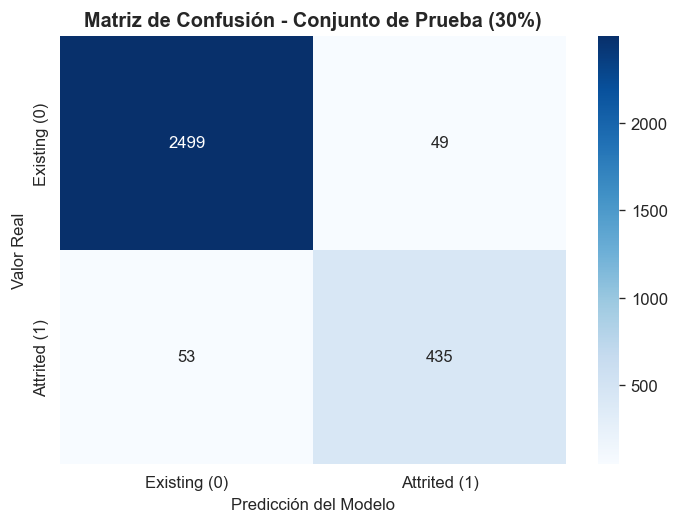

In [6]:
# Selección automática de los mejores hiperparámetros del modelo ganador (XGBoost)
if best_xgb_opt_score >= best_xgb_gs_score:
    winning_xgb_params = best_xgb_opt_params
    winning_opt_method = "Optimización Bayesiana (Optuna TPE)"
else:
    winning_xgb_params = best_xgb_gs_params
    winning_opt_method = "GridSearchCV"

final_xgb = XGBClassifier(**winning_xgb_params, random_state=42, eval_metric='logloss', n_jobs=-1)

final_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', final_xgb)
])

final_pipeline.fit(X_train, y_train)

# Evaluación sobre el 30% de prueba (datos intactos)
y_pred_test = final_pipeline.predict(X_test)
y_prob_test = final_pipeline.predict_proba(X_test)[:, 1]

test_metrics = {
    "Accuracy": round(float(accuracy_score(y_test, y_pred_test)), 4),
    "Precision": round(float(precision_score(y_test, y_pred_test)), 4),
    "Recall": round(float(recall_score(y_test, y_pred_test)), 4),
    "F1-Score": round(float(f1_score(y_test, y_pred_test)), 4),
    "ROC-AUC": round(float(roc_auc_score(y_test, y_prob_test)), 4)
}

print("=== EVALUACIÓN FINAL EN EL CONJUNTO DE PRUEBA (30%) ===")
print(f"Accuracy  : {test_metrics['Accuracy']:.4f}")
print(f"Precision : {test_metrics['Precision']:.4f}")
print(f"Recall    : {test_metrics['Recall']:.4f}")
print(f"F1-Score  : {test_metrics['F1-Score']:.4f}")
print(f"ROC-AUC   : {test_metrics['ROC-AUC']:.4f}\n")
print(classification_report(y_test, y_pred_test, target_names=['Existing Customer (0)', 'Attrited Customer (1)']))

# Almacenamiento del Pipeline para despliegue en Streamlit
raw_columns = [c for c in df.columns if c != 'Attrition_Flag']
model_bundle = {
    "pipeline": final_pipeline,
    "best_params": winning_xgb_params,
    "optimization_method": winning_opt_method,
    "test_metrics": test_metrics,
    "raw_columns": raw_columns
}
joblib.dump(model_bundle, "modelo_churn_pipeline.joblib")
print("Pipeline exportado exitosamente en: modelo_churn_pipeline.joblib")

# Matriz de confusión en el 30% de prueba
cm = confusion_matrix(y_test, y_pred_test)
plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Existing (0)', 'Attrited (1)'],
            yticklabels=['Existing (0)', 'Attrited (1)'])
plt.title("Matriz de Confusión - Conjunto de Prueba (30%)", fontweight='bold')
plt.xlabel("Predicción del Modelo")
plt.ylabel("Valor Real")
plt.tight_layout()
plt.show()